Name:- Asha Bhokare

Roll no.:- 23102A0032

Lab 7 R PROG

## 1. Install and Load Required R Packages

In [ ]:
install.packages(c(
  "readxl", "dplyr", "tidyr", "ggplot2", "lubridate",
  "cluster", "factoextra", "randomForest", "e1071",
  "caret", "pROC", "plotly", "scales"
), repos = "https://cloud.r-project.org")

library(readxl)
library(dplyr)
library(tidyr)
library(ggplot2)
library(lubridate)
library(cluster)
library(factoextra)
library(randomForest)
library(e1071)
library(caret)
library(pROC)
library(plotly)
library(scales)

set.seed(42)
options(scipen = 999)

cat("Packages loaded successfully.\n")


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Packages loaded successfully.


## 2. Download the UCI Online Retail Dataset

In [ ]:
url <- "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
zip_file <- "/content/online_retail.zip"
data_dir <- "/content/online_retail_data"

if (!file.exists(zip_file)) {
  download.file(url, zip_file, mode = "wb")
}

if (!dir.exists(data_dir)) {
  dir.create(data_dir, recursive = TRUE)
  unzip(zip_file, exdir = data_dir)
}

xlsx_file <- list.files(
  data_dir,
  pattern = "Online Retail\\.xlsx$",
  recursive = TRUE,
  full.names = TRUE
)[1]

retail <- read_excel(xlsx_file)

cat("Dataset dimensions:", dim(retail)[1], "rows x", dim(retail)[2], "columns\n")
head(retail)


Dataset dimensions: 541909 rows x 8 columns


InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<chr>
536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom


## 3. Understand the Dataset

In [ ]:
cat("Columns:\n")
print(names(retail))

cat("\nStructure:\n")
str(retail)

cat("\nMissing values:\n")
print(sort(colSums(is.na(retail)), decreasing = TRUE))

cat("\nDuplicate rows:", sum(duplicated(retail)), "\n")

summary(retail)


Columns:
[1] "InvoiceNo"   "StockCode"   "Description" "Quantity"    "InvoiceDate"
[6] "UnitPrice"   "CustomerID"  "Country"    

Structure:
tibble [541,909 × 8] (S3: tbl_df/tbl/data.frame)
 $ InvoiceNo  : chr [1:541909] "536365" "536365" "536365" "536365" ...
 $ StockCode  : chr [1:541909] "85123A" "71053" "84406B" "84029G" ...
 $ Description: chr [1:541909] "WHITE HANGING HEART T-LIGHT HOLDER" "WHITE METAL LANTERN" "CREAM CUPID HEARTS COAT HANGER" "KNITTED UNION FLAG HOT WATER BOTTLE" ...
 $ Quantity   : num [1:541909] 6 6 8 6 6 2 6 6 6 32 ...
 $ InvoiceDate: POSIXct[1:541909], format: "2010-12-01 08:26:00" "2010-12-01 08:26:00" ...
 $ UnitPrice  : num [1:541909] 2.55 3.39 2.75 3.39 3.39 7.65 4.25 1.85 1.85 1.69 ...
 $ CustomerID : num [1:541909] 17850 17850 17850 17850 17850 ...
 $ Country    : chr [1:541909] "United Kingdom" "United Kingdom" "United Kingdom" "United Kingdom" ...

Missing values:
 CustomerID Description   InvoiceNo   StockCode    Quantity InvoiceDate 
     135080   

     InvoiceNo          StockCode         Description        Quantity         
 Length   :541909   Length   :541909   Length   :541909   Min.   :-80995.000  
 N.unique : 25900   N.unique :  4070   N.unique :  4211   1st Qu.:     1.000  
 N.blank  :     0   N.blank  :     0   N.blank  :     0   Median :     3.000  
 Min.nchar:     6   Min.nchar:     1   Min.nchar:     1   Mean   :     9.552  
 Max.nchar:     7   Max.nchar:    12   Max.nchar:    35   3rd Qu.:    10.000  
                                       NAs      :  1454   Max.   : 80995.000  
                                                                              
  InvoiceDate                    UnitPrice            CustomerID    
 Min.   :2010-12-01 08:26:00   Min.   :-11062.060   Min.   :12346   
 1st Qu.:2011-03-28 11:34:00   1st Qu.:     1.250   1st Qu.:13953   
 Median :2011-07-19 17:17:00   Median :     2.080   Median :15152   
 Mean   :2011-07-04 13:34:57   Mean   :     4.611   Mean   :15288   
 3rd Qu.:2011-10-19 11:

## 4. Data Preprocessing

The preprocessing follows the problem statement:
- Remove duplicate rows.
- Convert InvoiceDate to datetime.
- Remove missing CustomerID values.
- Remove cancelled invoices.
- Remove non-positive Quantity and UnitPrice values.
- Create TotalPrice = Quantity × UnitPrice.

In [ ]:
retail <- retail %>%
  distinct() %>%
  mutate(
    InvoiceNo = as.character(InvoiceNo),
    CustomerID = as.character(CustomerID),
    InvoiceDate = as.POSIXct(InvoiceDate)
  ) %>%
  filter(
    !is.na(CustomerID),
    !is.na(InvoiceDate),
    !grepl("^C", InvoiceNo, ignore.case = TRUE),
    Quantity > 0,
    UnitPrice > 0
  ) %>%
  mutate(TotalPrice = Quantity * UnitPrice)

cat("Rows after preprocessing:", nrow(retail), "\n")
cat("Customers:", n_distinct(retail$CustomerID), "\n")
head(retail)


Rows after preprocessing: 392692 
Customers: 4338 


InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<chr>,<chr>,<dbl>
536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30


## 5. Exploratory Data Analysis

Unique invoices: 18532 
Unique countries: 37 
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00 
# A tibble: 10 × 2
   Country        TotalSales
   <chr>               <dbl>
 1 United Kingdom   7285025.
 2 Netherlands       285446.
 3 EIRE              265262.
 4 Germany           228678.
 5 France            208934.
 6 Australia         138454.
 7 Spain              61559.
 8 Switzerland        56444.
 9 Belgium            41196.
10 Sweden             38368.


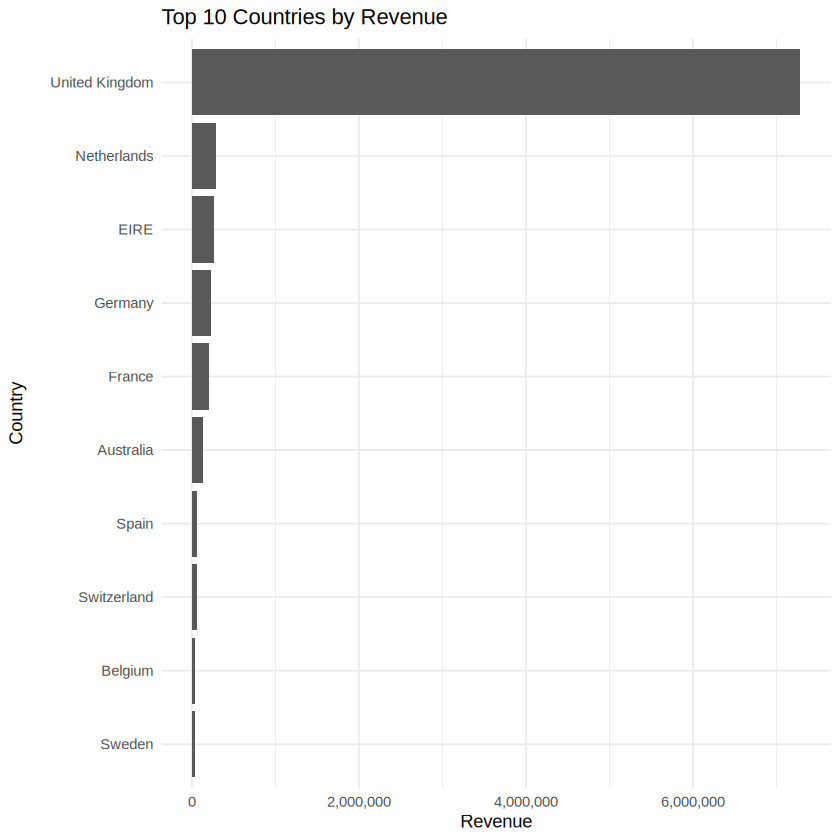

In [ ]:
cat("Unique invoices:", n_distinct(retail$InvoiceNo), "\n")
cat("Unique countries:", n_distinct(retail$Country), "\n")
cat("Date range:", as.character(min(retail$InvoiceDate)), "to",
    as.character(max(retail$InvoiceDate)), "\n")

country_sales <- retail %>%
  group_by(Country) %>%
  summarise(TotalSales = sum(TotalPrice), .groups = "drop") %>%
  arrange(desc(TotalSales)) %>%
  slice_head(n = 10)

print(country_sales)

ggplot(country_sales,
       aes(x = reorder(Country, TotalSales), y = TotalSales)) +
  geom_col() +
  coord_flip() +
  scale_y_continuous(labels = comma) +
  labs(
    title = "Top 10 Countries by Revenue",
    x = "Country",
    y = "Revenue"
  ) +
  theme_minimal()


## 6. Customer-Level Feature Engineering

Features:
- **Recency:** days since latest purchase.
- **Frequency:** number of unique invoices.
- **Monetary:** total spending.
- **Total Quantity:** total units purchased.
- **Average Transaction Value**
- **Purchase Frequency:** invoices per active month.

In [ ]:
reference_date <- max(retail$InvoiceDate) + days(1)

customer <- retail %>%
  group_by(CustomerID) %>%
  summarise(
    Recency = as.numeric(difftime(
      reference_date, max(InvoiceDate), units = "days"
    )),
    Frequency = n_distinct(InvoiceNo),
    Monetary = sum(TotalPrice),
    TotalQuantity = sum(Quantity),
    AverageTransactionValue = mean(TotalPrice),
    FirstPurchase = min(InvoiceDate),
    LastPurchase = max(InvoiceDate),
    Country = first(Country),
    .groups = "drop"
  ) %>%
  mutate(
    ActiveMonths = interval(
      floor_date(FirstPurchase, "month"),
      floor_date(LastPurchase, "month")
    ) %/% months(1) + 1,
    PurchaseFrequency = Frequency / ActiveMonths
  ) %>%
  drop_na()

cat("Customer-level dataset:", nrow(customer), "customers\n")
head(customer)


Customer-level dataset: 4338 customers


CustomerID,Recency,Frequency,Monetary,TotalQuantity,AverageTransactionValue,FirstPurchase,LastPurchase,Country,ActiveMonths,PurchaseFrequency
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dttm>,<dttm>,<chr>,<dbl>,<dbl>
12346,326.117361,1,77183.60,74215,77183.60000,2011-01-18 10:01:00,2011-01-18 10:01:00,United Kingdom,1,1.0000000
12347,2.873611,7,4310.00,2458,23.68132,2010-12-07 14:57:00,2011-12-07 15:52:00,Iceland,13,0.5384615
12348,75.984028,4,1797.24,2341,57.97548,2010-12-16 19:09:00,2011-09-25 13:13:00,Finland,10,0.4000000
12349,19.124306,1,1757.55,631,24.07603,2011-11-21 09:51:00,2011-11-21 09:51:00,Italy,1,1.0000000
12350,310.867361,1,334.40,197,19.67059,2011-02-02 16:01:00,2011-02-02 16:01:00,Norway,1,1.0000000
12352,36.925694,8,2506.04,536,29.48282,2011-02-16 12:33:00,2011-11-03 14:37:00,Norway,10,0.8000000


## 7. Outlier Treatment using IQR Capping

In [ ]:
feature_cols <- c(
  "Recency",
  "Frequency",
  "Monetary",
  "TotalQuantity",
  "AverageTransactionValue",
  "PurchaseFrequency"
)

iqr_cap <- function(x) {
  q1 <- quantile(x, 0.25, na.rm = TRUE)
  q3 <- quantile(x, 0.75, na.rm = TRUE)
  iqr <- q3 - q1
  lower <- q1 - 1.5 * iqr
  upper <- q3 + 1.5 * iqr
  pmin(pmax(x, lower), upper)
}

customer_model <- customer

for (col in feature_cols) {
  customer_model[[col]] <- iqr_cap(customer_model[[col]])
}

summary(customer_model[feature_cols])


    Recency         Frequency         Monetary       TotalQuantity   
 Min.   :  1.00   Min.   : 1.000   Min.   :   3.75   Min.   :   1.0  
 1st Qu.: 18.07   1st Qu.: 1.000   1st Qu.: 306.48   1st Qu.: 159.0  
 Median : 51.09   Median : 2.000   Median : 668.57   Median : 378.0  
 Mean   : 92.00   Mean   : 3.487   Mean   :1159.01   Mean   : 682.1  
 3rd Qu.:142.73   3rd Qu.: 5.000   3rd Qu.:1660.60   3rd Qu.: 989.8  
 Max.   :329.72   Max.   :11.000   Max.   :3691.77   Max.   :2235.9  
 AverageTransactionValue PurchaseFrequency
 Min.   : 2.137          Min.   :0.1538   
 1st Qu.:12.393          1st Qu.:0.5385   
 Median :17.755          Median :1.0000   
 Mean   :20.085          Mean   :0.8533   
 3rd Qu.:24.879          3rd Qu.:1.0000   
 Max.   :43.608          Max.   :1.6923   

## 8. Log Transformation and Feature Scaling

In [ ]:
model_features <- customer_model[, feature_cols]

model_features_log <- as.data.frame(
  lapply(model_features, log1p)
)

X_scaled <- scale(model_features_log)

cat("Scaled feature matrix dimensions:",
    dim(X_scaled)[1], "x", dim(X_scaled)[2], "\n")

head(X_scaled)


Scaled feature matrix dimensions: 4338 x 6 


Recency,Frequency,Monetary,TotalQuantity,AverageTransactionValue,PurchaseFrequency
1.4864802,-1.0406605,1.5251879,1.4547232,1.5104648,0.47098987
-1.9187074,1.2958187,1.5251879,1.4547232,0.5337825,-0.79934393
0.3759730,0.5036683,0.8782859,1.4547232,1.5104648,-1.25598403
-0.6538965,-1.0406605,0.8582210,0.4333250,0.5599640,0.47098987
1.4498341,-1.0406605,-0.6313739,-0.5045774,0.2411447,0.47098987
-0.1674662,1.4943318,1.1770231,0.3016920,0.8821672,-0.03915211


## 9. Elbow Method for K-Means

Warning message:
“did not converge in 10 iterations”


   K   Inertia
1  2 16687.344
2  3 13300.490
3  4 11784.342
4  5 10716.052
5  6  9696.298
6  7  9002.111
7  8  8438.205
8  9  7964.774
9 10  7579.280


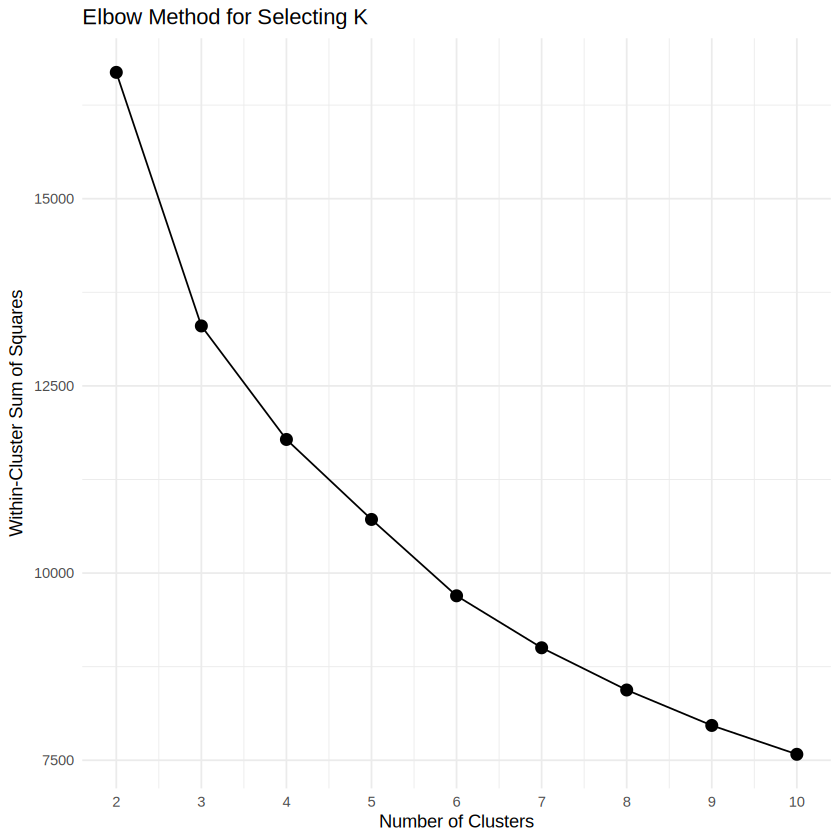

In [ ]:
k_values <- 2:10

inertia <- sapply(k_values, function(k) {
  km <- kmeans(X_scaled, centers = k, nstart = 20)
  km$tot.withinss
})

elbow_df <- data.frame(
  K = k_values,
  Inertia = inertia
)

print(elbow_df)

ggplot(elbow_df, aes(x = K, y = Inertia)) +
  geom_line() +
  geom_point(size = 3) +
  scale_x_continuous(breaks = k_values) +
  labs(
    title = "Elbow Method for Selecting K",
    x = "Number of Clusters",
    y = "Within-Cluster Sum of Squares"
  ) +
  theme_minimal()


## 10. Silhouette Analysis and K-Means Clustering

In [ ]:
silhouette_scores <- sapply(k_values, function(k) {
  km <- kmeans(X_scaled, centers = k, nstart = 20)
  sil <- silhouette(km$cluster, dist(X_scaled))
  mean(sil[, 3])
})

silhouette_df <- data.frame(
  K = k_values,
  SilhouetteScore = silhouette_scores
)

print(silhouette_df)

optimal_k <- silhouette_df$K[
  which.max(silhouette_df$SilhouetteScore)
]

cat("Selected K:", optimal_k, "\n")

kmeans_model <- kmeans(
  X_scaled,
  centers = optimal_k,
  nstart = 25
)

customer_model$KMeansCluster <- factor(kmeans_model$cluster)

kmeans_silhouette <- mean(
  silhouette(kmeans_model$cluster, dist(X_scaled))[, 3]
)

cat("K-Means Silhouette Score:",
    round(kmeans_silhouette, 4), "\n")


Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 216900)”
Warning message:
“did not converge in 10 iterations”


   K SilhouetteScore
1  2       0.3135717
2  3       0.2757413
3  4       0.2515546
4  5       0.2263464
5  6       0.2106479
6  7       0.2134953
7  8       0.2170370
8  9       0.2148062
9 10       0.2085426
Selected K: 2 
K-Means Silhouette Score: 0.3136 


## 11. Hierarchical Clustering and Dendrogram

Hierarchical Silhouette Score: 0.2824 


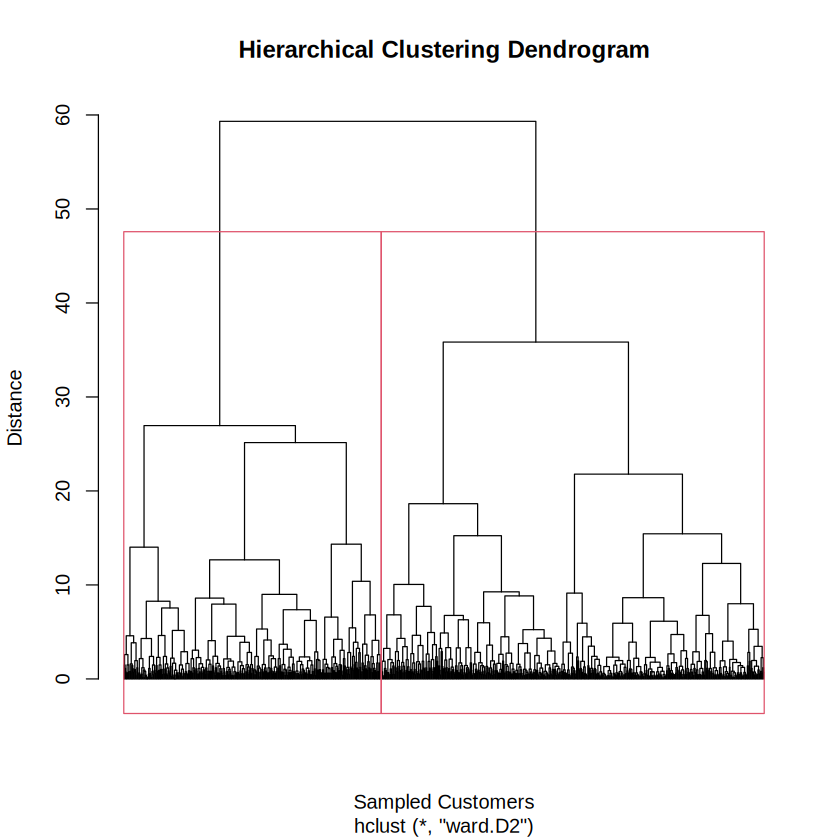

In [ ]:
sample_size <- min(1000, nrow(X_scaled))
sample_index <- sample(seq_len(nrow(X_scaled)), sample_size)

X_sample <- X_scaled[sample_index, ]

hc_sample <- hclust(
  dist(X_sample),
  method = "ward.D2"
)

plot(
  hc_sample,
  labels = FALSE,
  hang = -1,
  main = "Hierarchical Clustering Dendrogram",
  xlab = "Sampled Customers",
  ylab = "Distance"
)

rect.hclust(hc_sample, k = optimal_k)

hc_model <- hclust(
  dist(X_scaled),
  method = "ward.D2"
)

hc_clusters <- cutree(
  hc_model,
  k = optimal_k
)

hc_silhouette <- mean(
  silhouette(hc_clusters, dist(X_scaled))[, 3]
)

cat("Hierarchical Silhouette Score:",
    round(hc_silhouette, 4), "\n")


## 12. Compare Clustering Methods

        Method SilhouetteScore
1      K-Means       0.3135717
2 Hierarchical       0.2824077


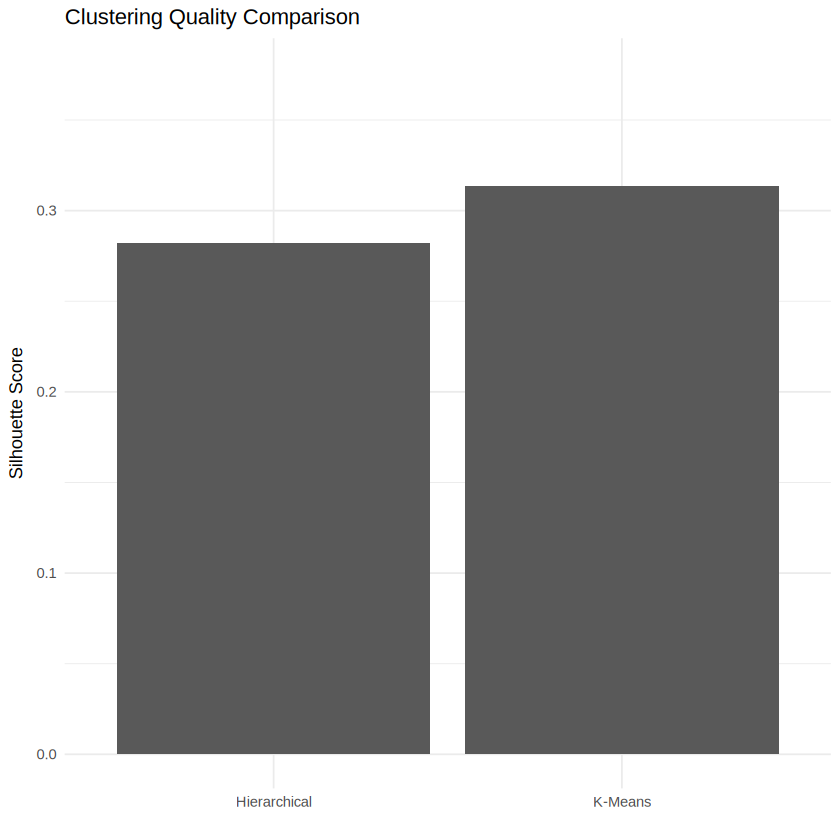

In [ ]:
cluster_comparison <- data.frame(
  Method = c("K-Means", "Hierarchical"),
  SilhouetteScore = c(
    kmeans_silhouette,
    hc_silhouette
  )
)

print(cluster_comparison)

ggplot(cluster_comparison,
       aes(x = Method, y = SilhouetteScore)) +
  geom_col() +
  ylim(0, max(cluster_comparison$SilhouetteScore) * 1.2) +
  labs(
    title = "Clustering Quality Comparison",
    x = "",
    y = "Silhouette Score"
  ) +
  theme_minimal()


## 13. PCA 2D Visualization

Explained variance by first 3 PCs:
    PC1     PC2     PC3 
0.50498 0.17899 0.16204 


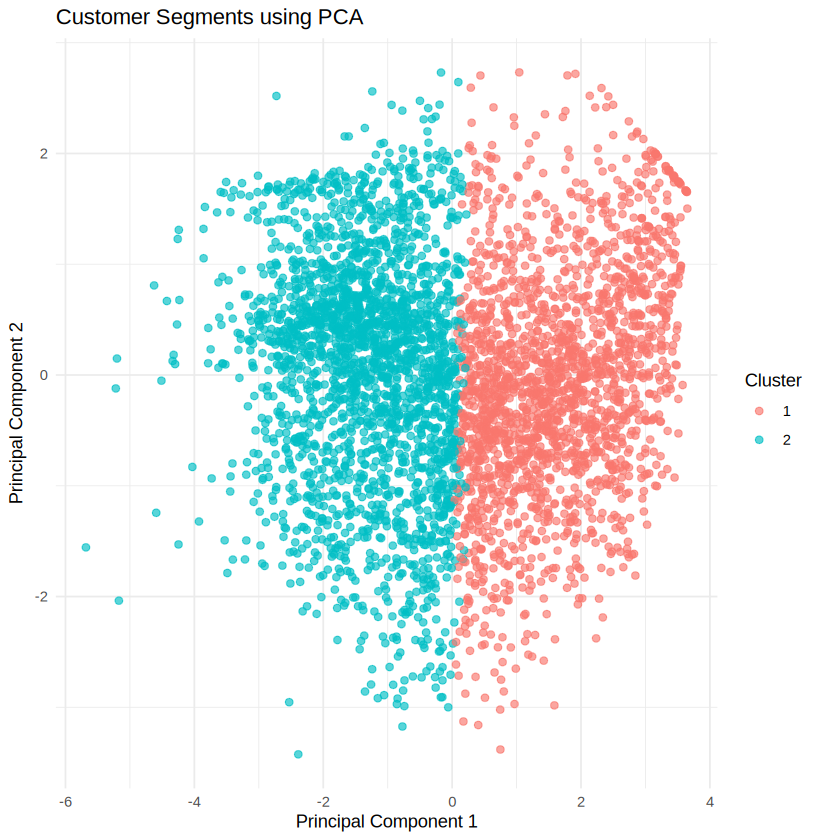

In [ ]:
pca_model <- prcomp(
  X_scaled,
  center = FALSE,
  scale. = FALSE
)

pca_data <- data.frame(
  PCA1 = pca_model$x[, 1],
  PCA2 = pca_model$x[, 2],
  Cluster = customer_model$KMeansCluster
)

explained_variance <- summary(pca_model)$importance[2, 1:3]

cat("Explained variance by first 3 PCs:\n")
print(explained_variance)

ggplot(pca_data,
       aes(x = PCA1, y = PCA2, color = Cluster)) +
  geom_point(alpha = 0.65, size = 1.8) +
  labs(
    title = "Customer Segments using PCA",
    x = "Principal Component 1",
    y = "Principal Component 2",
    color = "Cluster"
  ) +
  theme_minimal()


## 14. Interactive 3D Plotly Visualization

In [ ]:
pca3_data <- data.frame(
  PCA1 = pca_model$x[, 1],
  PCA2 = pca_model$x[, 2],
  PCA3 = pca_model$x[, 3],
  Cluster = customer_model$KMeansCluster,
  CustomerID = customer_model$CustomerID,
  Recency = customer_model$Recency,
  Frequency = customer_model$Frequency,
  Monetary = customer_model$Monetary
)

fig <- plot_ly(
  pca3_data,
  x = ~PCA1,
  y = ~PCA2,
  z = ~PCA3,
  color = ~Cluster,
  type = "scatter3d",
  mode = "markers",
  text = ~paste(
    "Customer:", CustomerID,
    "<br>Recency:", round(Recency, 1),
    "<br>Frequency:", round(Frequency, 1),
    "<br>Monetary:", round(Monetary, 2)
  ),
  hoverinfo = "text"
)

fig <- fig %>%
  layout(
    title = "Interactive 3D Customer Clusters",
    scene = list(
      xaxis = list(title = "PCA1"),
      yaxis = list(title = "PCA2"),
      zaxis = list(title = "PCA3")
    )
  )

fig


HTML widgets cannot be represented in plain text (need html)

## 15. Cluster-Wise Customer Profiling

# A tibble: 2 × 8
  KMeansCluster Customers Recency Frequency Monetary TotalQuantity
  <fct>             <int>   <dbl>     <dbl>    <dbl>         <dbl>
1 1                  1961    37.1      5.85    2092.         1240.
2 2                  2377   137.       1.53     389.          222.
# ℹ 2 more variables: AverageTransactionValue <dbl>, PurchaseFrequency <dbl>


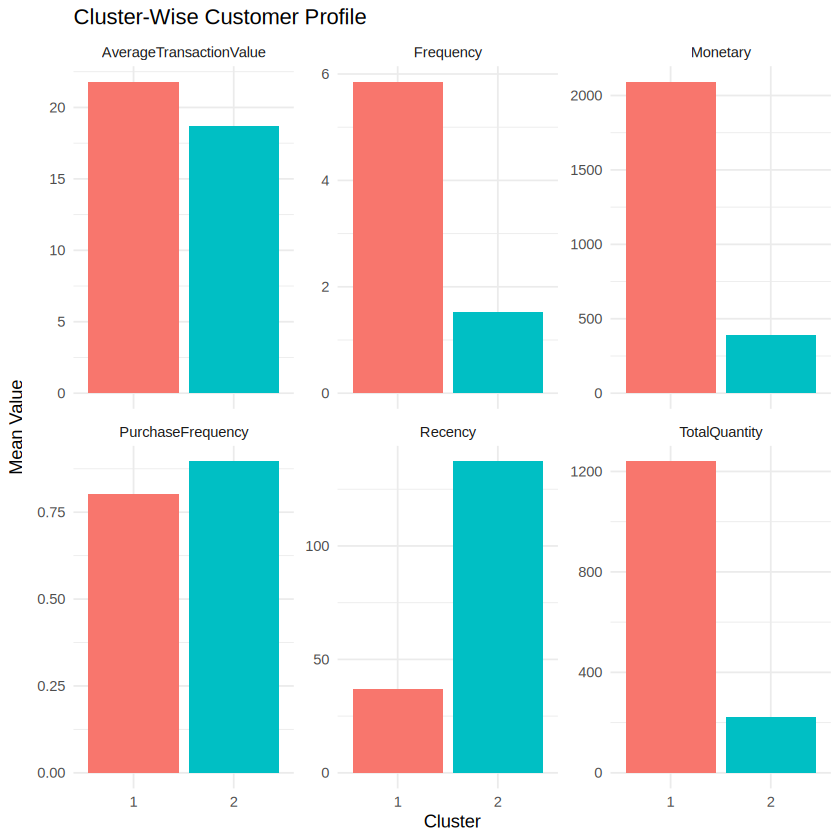

In [ ]:
cluster_profile <- customer_model %>%
  group_by(KMeansCluster) %>%
  summarise(
    Customers = n(),
    Recency = mean(Recency),
    Frequency = mean(Frequency),
    Monetary = mean(Monetary),
    TotalQuantity = mean(TotalQuantity),
    AverageTransactionValue = mean(AverageTransactionValue),
    PurchaseFrequency = mean(PurchaseFrequency),
    .groups = "drop"
  )

print(cluster_profile)

cluster_profile_long <- cluster_profile %>%
  pivot_longer(
    cols = -c(KMeansCluster, Customers),
    names_to = "Feature",
    values_to = "MeanValue"
  )

ggplot(
  cluster_profile_long,
  aes(x = KMeansCluster, y = MeanValue, fill = KMeansCluster)
) +
  geom_col(show.legend = FALSE) +
  facet_wrap(~Feature, scales = "free_y") +
  labs(
    title = "Cluster-Wise Customer Profile",
    x = "Cluster",
    y = "Mean Value"
  ) +
  theme_minimal()


## 16. Identify the High-Value Customer Segment

A customer is initially considered high-value if:
- Monetary value is at or above the 75th percentile, and
- Frequency is at or above the median.

The cluster containing the highest proportion of these customers becomes the high-value cluster.

In [ ]:
monetary_threshold <- quantile(
  customer_model$Monetary,
  0.75
)

frequency_threshold <- median(
  customer_model$Frequency
)

customer_model$HighValueRule <- ifelse(
  customer_model$Monetary >= monetary_threshold &
    customer_model$Frequency >= frequency_threshold,
  1,
  0
)

high_value_by_cluster <- customer_model %>%
  group_by(KMeansCluster) %>%
  summarise(
    HighValueCustomers = sum(HighValueRule),
    Customers = n(),
    HighValueRate = mean(HighValueRule),
    .groups = "drop"
  ) %>%
  arrange(desc(HighValueRate))

print(high_value_by_cluster)

high_value_cluster <- as.character(
  high_value_by_cluster$KMeansCluster[1]
)

customer_model$HighValueTarget <- ifelse(
  as.character(customer_model$KMeansCluster) ==
    high_value_cluster,
  1,
  0
)

cat("High-value cluster:", high_value_cluster, "\n")
cat("High-value customers:",
    sum(customer_model$HighValueTarget), "\n")


# A tibble: 2 × 4
  KMeansCluster HighValueCustomers Customers HighValueRate
  <fct>                      <dbl>     <int>         <dbl>
1 1                           1052      1961      0.536   
2 2                              2      2377      0.000841
High-value cluster: 1 
High-value customers: 1961 


## 17. Prepare Data for Supervised Learning

In [ ]:
X <- customer_model[, feature_cols]
X <- as.data.frame(lapply(X, log1p))

y <- factor(
  customer_model$HighValueTarget,
  levels = c(0, 1),
  labels = c("Other", "HighValue")
)

train_index <- createDataPartition(
  y,
  p = 0.80,
  list = FALSE
)

X_train <- X[train_index, ]
X_test <- X[-train_index, ]

y_train <- y[train_index]
y_test <- y[-train_index]

svm_preprocess <- preProcess(
  X_train,
  method = c("center", "scale")
)

X_train_scaled <- predict(
  svm_preprocess,
  X_train
)

X_test_scaled <- predict(
  svm_preprocess,
  X_test
)

cat("Training rows:", nrow(X_train), "\n")
cat("Testing rows:", nrow(X_test), "\n")
print(table(y))


Training rows: 3471 
Testing rows: 867 
y
    Other HighValue 
     2377      1961 


## 18. Random Forest Model

In [ ]:
rf_model <- randomForest(
  x = X_train,
  y = y_train,
  ntree = 300,
  importance = TRUE
)

rf_pred <- predict(
  rf_model,
  X_test,
  type = "response"
)

rf_prob <- predict(
  rf_model,
  X_test,
  type = "prob"
)[, "HighValue"]

cat("Random Forest Classification Report:\n")
print(confusionMatrix(rf_pred, y_test, positive = "HighValue"))


Random Forest Classification Report:
Confusion Matrix and Statistics

           Reference
Prediction  Other HighValue
  Other       470         7
  HighValue     5       385
                                             
               Accuracy : 0.9862             
                 95% CI : (0.9759, 0.9928)   
    No Information Rate : 0.5479             
    P-Value [Acc > NIR] : <0.0000000000000002
                                             
                  Kappa : 0.972              
                                             
 Mcnemar's Test P-Value : 0.7728             
                                             
            Sensitivity : 0.9821             
            Specificity : 0.9895             
         Pos Pred Value : 0.9872             
         Neg Pred Value : 0.9853             
             Prevalence : 0.4521             
         Detection Rate : 0.4441             
   Detection Prevalence : 0.4498             
      Balanced Accuracy : 0.9858           

## 19. SVM Model

In [ ]:
svm_model <- svm(
  x = X_train_scaled,
  y = y_train,
  kernel = "radial",
  probability = TRUE
)

svm_pred <- predict(
  svm_model,
  X_test_scaled,
  probability = TRUE
)

svm_prob_matrix <- attr(
  svm_pred,
  "probabilities"
)

svm_prob <- svm_prob_matrix[, "HighValue"]

cat("SVM Classification Report:\n")
print(confusionMatrix(svm_pred, y_test, positive = "HighValue"))


SVM Classification Report:
Confusion Matrix and Statistics

           Reference
Prediction  Other HighValue
  Other       473         5
  HighValue     2       387
                                             
               Accuracy : 0.9919             
                 95% CI : (0.9834, 0.9967)   
    No Information Rate : 0.5479             
    P-Value [Acc > NIR] : <0.0000000000000002
                                             
                  Kappa : 0.9837             
                                             
 Mcnemar's Test P-Value : 0.4497             
                                             
            Sensitivity : 0.9872             
            Specificity : 0.9958             
         Pos Pred Value : 0.9949             
         Neg Pred Value : 0.9895             
             Prevalence : 0.4521             
         Detection Rate : 0.4464             
   Detection Prevalence : 0.4487             
      Balanced Accuracy : 0.9915             
       

## 20. Calculate Accuracy, Precision, Recall, F1-Score and ROC-AUC

In [ ]:
calculate_metrics <- function(actual, predicted, probability, model_name) {

  cm <- confusionMatrix(
    predicted,
    actual,
    positive = "HighValue"
  )

  roc_obj <- roc(
    response = actual,
    predictor = probability,
    levels = c("Other", "HighValue"),
    direction = "<"
  )

  data.frame(
    Model = model_name,
    Accuracy = as.numeric(cm$overall["Accuracy"]),
    Precision = as.numeric(cm$byClass["Pos Pred Value"]),
    Recall = as.numeric(cm$byClass["Sensitivity"]),
    F1_Score = 2 *
      (as.numeric(cm$byClass["Pos Pred Value"]) *
       as.numeric(cm$byClass["Sensitivity"])) /
      (as.numeric(cm$byClass["Pos Pred Value"]) +
       as.numeric(cm$byClass["Sensitivity"])),
    ROC_AUC = as.numeric(auc(roc_obj))
  )
}

metrics <- bind_rows(
  calculate_metrics(
    y_test, rf_pred, rf_prob, "Random Forest"
  ),
  calculate_metrics(
    y_test, svm_pred, svm_prob, "SVM"
  )
)

print(metrics)


          Model  Accuracy Precision    Recall  F1_Score   ROC_AUC
1 Random Forest 0.9861592 0.9871795 0.9821429 0.9846547 0.9990736
2           SVM 0.9919262 0.9948586 0.9872449 0.9910371 0.9998980


## 21. Confusion Matrices

[1] "Random Forest:"
           Reference
Prediction  Other HighValue
  Other       470         7
  HighValue     5       385
[1] "SVM:"
           Reference
Prediction  Other HighValue
  Other       473         5
  HighValue     2       387


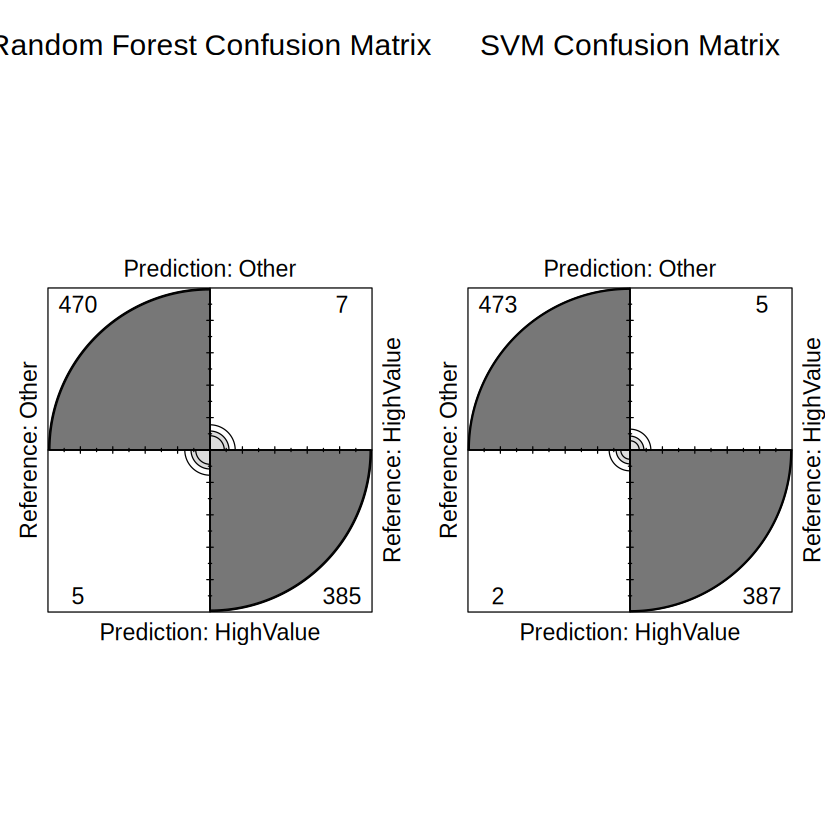

In [ ]:
par(mfrow = c(1, 2))

cm_rf <- confusionMatrix(
  rf_pred,
  y_test,
  positive = "HighValue"
)$table

cm_svm <- confusionMatrix(
  svm_pred,
  y_test,
  positive = "HighValue"
)$table

fourfoldplot(
  cm_rf,
  color = c("#DDDDDD", "#777777"),
  main = "Random Forest Confusion Matrix"
)

fourfoldplot(
  cm_svm,
  color = c("#DDDDDD", "#777777"),
  main = "SVM Confusion Matrix"
)

par(mfrow = c(1, 1))

print("Random Forest:")
print(cm_rf)

print("SVM:")
print(cm_svm)


## 22. ROC Curve Comparison

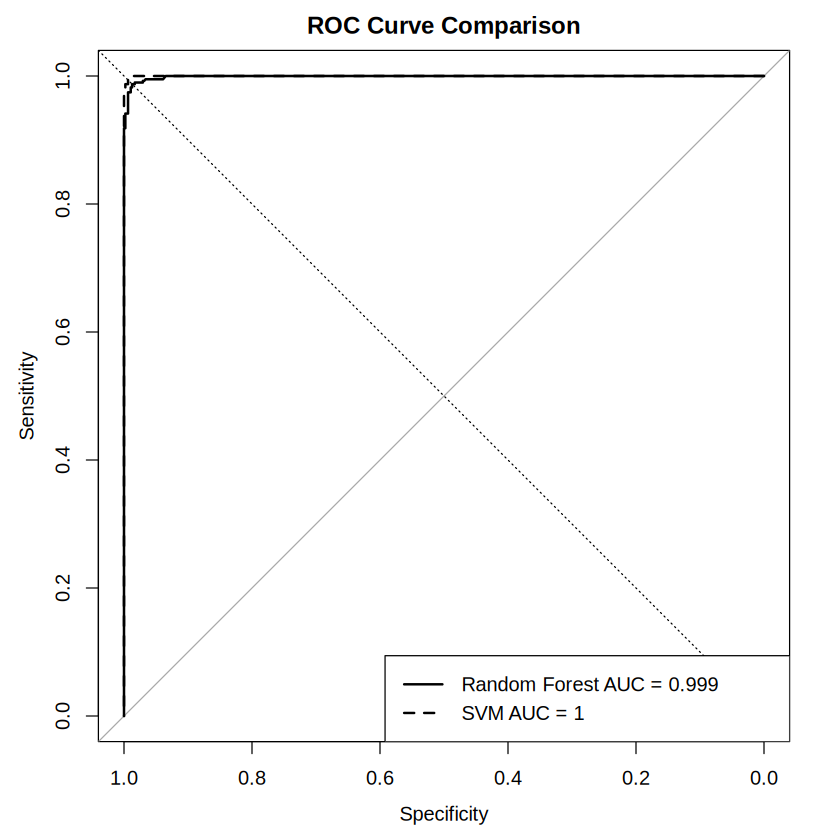

In [ ]:
roc_rf <- roc(
  y_test,
  rf_prob,
  levels = c("Other", "HighValue"),
  direction = "<"
)

roc_svm <- roc(
  y_test,
  svm_prob,
  levels = c("Other", "HighValue"),
  direction = "<"
)

plot(
  roc_rf,
  main = "ROC Curve Comparison",
  lwd = 2
)

lines(
  roc_svm,
  lwd = 2,
  lty = 2
)

abline(
  a = 0,
  b = 1,
  lty = 3
)

legend(
  "bottomright",
  legend = c(
    paste0("Random Forest AUC = ", round(auc(roc_rf), 3)),
    paste0("SVM AUC = ", round(auc(roc_svm), 3))
  ),
  lty = c(1, 2),
  lwd = 2
)


## 23. Random Forest Feature Importance

                                        Feature Importance
Monetary                               Monetary  590.38583
TotalQuantity                     TotalQuantity  467.04210
Frequency                             Frequency  385.64629
Recency                                 Recency  184.20192
PurchaseFrequency             PurchaseFrequency   58.88531
AverageTransactionValue AverageTransactionValue   29.52858


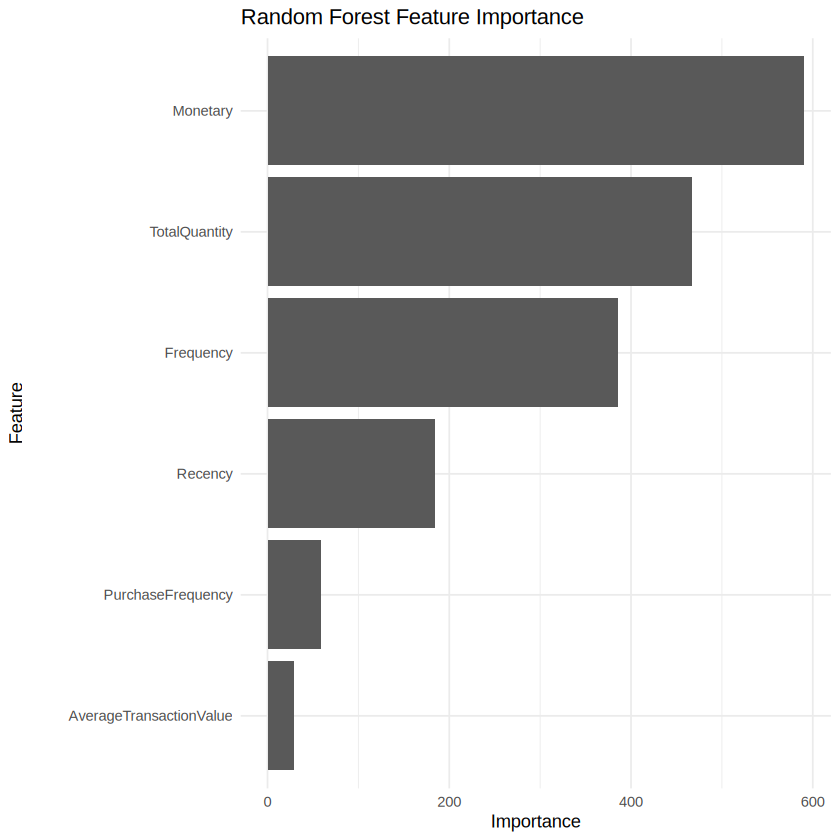

In [ ]:
importance_values <- importance(
  rf_model,
  type = 2
)

importance_df <- data.frame(
  Feature = rownames(importance_values),
  Importance = importance_values[, 1]
) %>%
  arrange(desc(Importance))

print(importance_df)

ggplot(
  importance_df,
  aes(
    x = reorder(Feature, Importance),
    y = Importance
  )
) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Random Forest Feature Importance",
    x = "Feature",
    y = "Importance"
  ) +
  theme_minimal()


## 24. Segment-Wise Marketing Recommendations

In [ ]:
profile <- customer_model %>%
  group_by(KMeansCluster) %>%
  summarise(
    Recency = mean(Recency),
    Frequency = mean(Frequency),
    Monetary = mean(Monetary),
    .groups = "drop"
  )

median_recency <- median(profile$Recency)
median_monetary <- median(profile$Monetary)
median_frequency <- median(profile$Frequency)

for (i in seq_len(nrow(profile))) {

  cluster <- as.character(profile$KMeansCluster[i])
  recency <- profile$Recency[i]
  frequency <- profile$Frequency[i]
  monetary <- profile$Monetary[i]

  if (cluster == high_value_cluster) {
    strategy <- "High-value customers: loyalty rewards, VIP benefits, personalized offers, cross-selling and early access."
  } else if (recency <= median_recency &&
             monetary >= median_monetary) {
    strategy <- "Active valuable customers: personalized recommendations, cross-selling and engagement campaigns."
  } else if (recency > median_recency) {
    strategy <- "At-risk/inactive customers: reactivation campaigns, reminders and limited-time offers."
  } else if (frequency <= median_frequency) {
    strategy <- "Low-frequency customers: onboarding offers, bundles and incentives to encourage repeat purchases."
  } else {
    strategy <- "Regular customers: personalized promotions and recommendations to increase frequency and basket value."
  }

  cat(
    "\nCluster", cluster, ":\n",
    strategy, "\n"
  )
}



Cluster 1 :
 High-value customers: loyalty rewards, VIP benefits, personalized offers, cross-selling and early access. 

Cluster 2 :
 At-risk/inactive customers: reactivation campaigns, reminders and limited-time offers. 


## 25. Final Results Summary

In [ ]:
cat("============================================================\n")
cat("FINAL RESULTS\n")
cat("============================================================\n")

cat("Customers analyzed:", nrow(customer_model), "\n")
cat("Optimal K:", optimal_k, "\n")
cat("K-Means Silhouette Score:",
    round(kmeans_silhouette, 4), "\n")
cat("Hierarchical Silhouette Score:",
    round(hc_silhouette, 4), "\n")
cat("High-value cluster:",
    high_value_cluster, "\n")
cat("High-value customers:",
    sum(customer_model$HighValueTarget), "\n\n")

print(metrics)

cat("\nCluster sizes:\n")
print(
  customer_model %>%
    count(KMeansCluster)
)


FINAL RESULTS
Customers analyzed: 4338 
Optimal K: 2 
K-Means Silhouette Score: 0.3136 
Hierarchical Silhouette Score: 0.2824 
High-value cluster: 1 
High-value customers: 1961 

          Model  Accuracy Precision    Recall  F1_Score   ROC_AUC
1 Random Forest 0.9861592 0.9871795 0.9821429 0.9846547 0.9990736
2           SVM 0.9919262 0.9948586 0.9872449 0.9910371 0.9998980

Cluster sizes:
# A tibble: 2 × 2
  KMeansCluster     n
  <fct>         <int>
1 1              1961
2 2              2377


# Conclusion

This R programming experiment implements an end-to-end customer analytics workflow using the UCI Online Retail Dataset. Transaction data is cleaned and transformed into customer-level RFM and purchasing features. K-Means clustering is used for customer segmentation, with the Elbow Method and Silhouette Score used to support cluster selection and validation.

Hierarchical Clustering and a dendrogram provide a second clustering perspective. PCA reduces the feature space for visualization, while Plotly provides an interactive 3D customer-cluster visualization.

A high-value customer segment is identified from purchasing behavior and used as the target for supervised prediction. Random Forest and SVM models are evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC and Confusion Matrix. Random Forest feature importance identifies influential customer attributes.

Finally, segment-specific marketing recommendations are generated from the customer profiles.

**Run all cells from top to bottom in Google Colab. Numerical results and plots are generated automatically from the dataset.**
